# Fabric Defect Detection using a CNN built from scratch



## 2. Import Required Libraries


In [ ]:
%pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 15.7 MB/s  0:00:21
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 60.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [tensorflow]


In [ ]:
import os
import zipfile
import random

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Fix the random seeds so that results are (mostly) repeatable
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


TensorFlow version: 2.21.0
GPU available: False


## 3. Dataset Upload



In [ ]:
from google.colab import files

# This opens a file chooser in the browser. Select the dataset ZIP file.
uploaded_files = files.upload()

# Keep the name of the first uploaded file
zip_file_name = list(uploaded_files.keys())[0]
print("Uploaded file:", zip_file_name)
print("Size in MB:", round(os.path.getsize(zip_file_name) / (1024 * 1024), 2))

Saving archive.zip to archive.zip
Uploaded file: archive.zip
Size in MB: 398.99


In [ ]:
import os
import zipfile

print("Selected file:", zip_file_name)
print("File size:", os.path.getsize(zip_file_name), "bytes")
print("Is valid ZIP:", zipfile.is_zipfile(zip_file_name))

Selected file: archive.zip
File size: 418368603 bytes
Is valid ZIP: True


In [ ]:
import os

for file in os.listdir("/content"):
    print(file)

.config
archive.zip
sample_data


In [ ]:
!apt-get install -y unrar

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:7.0.7-1build1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


## 4. Dataset Extraction



In [ ]:
import os

print("Uploaded filename:", zip_file_name)
print("Files available:", os.listdir("/content"))

Uploaded filename: archive.zip
Files available: ['.config', 'archive.zip', 'fabric_dataset', 'sample_data']


In [ ]:
import os
import zipfile

extract_folder = "fabric_dataset"

os.makedirs(extract_folder, exist_ok=True)

with zipfile.ZipFile("archive.zip", "r") as zip_ref:
    zip_ref.extractall(extract_folder)

print("Extraction finished!")
print("Folders:", os.listdir(extract_folder))

Extraction finished!
Folders: ['512x512_Veri']


In [ ]:
for root, dirs, files in os.walk("fabric_dataset"):
    print(root, ":", len(files), "files")

fabric_dataset : 0 files
fabric_dataset/512x512_Veri : 0 files
fabric_dataset/512x512_Veri/Hatasiz : 1650 files
fabric_dataset/512x512_Veri/Hatali : 1263 files


In [ ]:
dataset_path = "fabric_dataset/512x512_Veri"

print("Dataset folders:", os.listdir(dataset_path))

Dataset folders: ['Hatasiz', 'Hatali']


## 5. Dataset Exploration


In [ ]:
# ---- Step 1: print the folder structure (only the first 2 levels of detail) ----
print("Folder structure:")
for folder_path, sub_folders, file_names in os.walk(extract_folder):
    if "__MACOSX" in folder_path:
        continue  # skip hidden junk folders created by macOS
    depth = folder_path.replace(extract_folder, "").count(os.sep)
    if depth <= 3:
        print("  " * depth + os.path.basename(folder_path) + "/   (" + str(len(file_names)) + " files)")

Folder structure:
fabric_dataset/   (0 files)
  512x512_Veri/   (0 files)
    Hatasiz/   (1650 files)
    Hatali/   (1263 files)


In [ ]:
# ---- Step 2: find all image files in all sub-folders ----
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_paths = []
for folder_path, sub_folders, file_names in os.walk(extract_folder):
    if "__MACOSX" in folder_path:
        continue
    for file_name in file_names:
        if file_name.lower().endswith(image_extensions) and not file_name.startswith("."):
            image_paths.append(os.path.join(folder_path, file_name))

print("Total number of images found:", len(image_paths))

# ---- Step 3: get the label of each image from its parent folder name ----
# Folder names like "train" or "images" are not class names, so we detect them.
not_class_names = ["train", "test", "valid", "val", "validation", "images", "image", "data", "dataset"]

image_labels = []
unknown_label_count = 0
for path in image_paths:
    parent_folder_name = os.path.basename(os.path.dirname(path)).strip().lower()
    if parent_folder_name in not_class_names:
        unknown_label_count = unknown_label_count + 1
    image_labels.append(parent_folder_name)

class_names_found = sorted(set(image_labels))
print("Number of classes found:", len(class_names_found))
print("Class names:", class_names_found)

# Safety check: stop with a clear message if the labels are not in folder names
if unknown_label_count > 0 or len(class_names_found) < 2:
    raise ValueError(
        "Could not read labels from folder names. Images sit directly inside folders such as "
        "train/valid/test/images, so the labels may be stored in an annotation file instead. "
        "Please look at the folder structure printed above."
    )

Total number of images found: 2912
Number of classes found: 2
Class names: ['hatali', 'hatasiz']


Images per class:
   hatali : 1263
   hatasiz : 1649


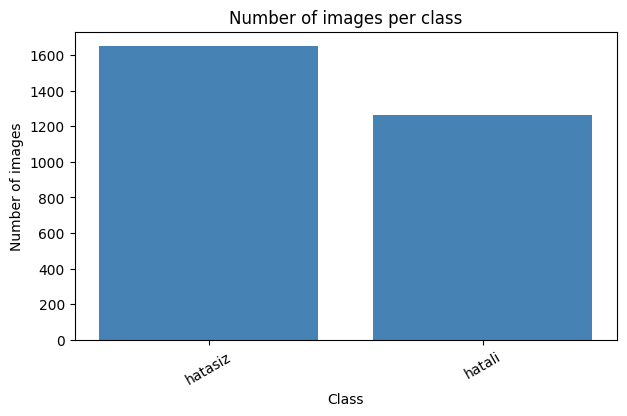

In [ ]:
# ---- Step 4: images per class ----
class_counts = {}
for label in image_labels:
    class_counts[label] = class_counts.get(label, 0) + 1

print("Images per class:")
for class_name in class_names_found:
    print("  ", class_name, ":", class_counts[class_name])

plt.figure(figsize=(7, 4))
plt.bar(list(class_counts.keys()), list(class_counts.values()), color="steelblue")
plt.title("Number of images per class")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=30)
plt.show()

In [ ]:
# ---- Step 5: image sizes, formats and total dataset size ----
from PIL import Image  # PIL is used only to read the width and height

size_counts = {}
format_counts = {}
total_size_bytes = 0

for path in image_paths:
    total_size_bytes = total_size_bytes + os.path.getsize(path)

    extension = os.path.splitext(path)[1].lower()
    format_counts[extension] = format_counts.get(extension, 0) + 1

    with Image.open(path) as img:
        size_text = str(img.size[0]) + "x" + str(img.size[1])   # width x height
        size_counts[size_text] = size_counts.get(size_text, 0) + 1

print("Image formats:", format_counts)
print("Number of different image sizes:", len(size_counts))
print("Most common sizes (width x height):")
sorted_sizes = sorted(size_counts.items(), key=lambda item: item[1], reverse=True)
for size_text, how_many in sorted_sizes[:5]:
    print("  ", size_text, ":", how_many, "images")

total_size_mb = total_size_bytes / (1024 * 1024)
print("Total size of all images:", round(total_size_mb, 1), "MB")

# ---- Check the instructor's requirements ----
print()
print("Requirement check")
print("  At least 2000 images?   ", len(image_paths) >= 2000, "(" + str(len(image_paths)) + " images)")
print("  At most 2.5 GB in size? ", total_size_mb <= 2.5 * 1024, "(" + str(round(total_size_mb, 1)) + " MB)")

Image formats: {'.jpg': 2912}
Number of different image sizes: 1
Most common sizes (width x height):
   512x512 : 2912 images
Total size of all images: 400.3 MB

Requirement check
  At least 2000 images?    True (2912 images)
  At most 2.5 GB in size?  True (400.3 MB)


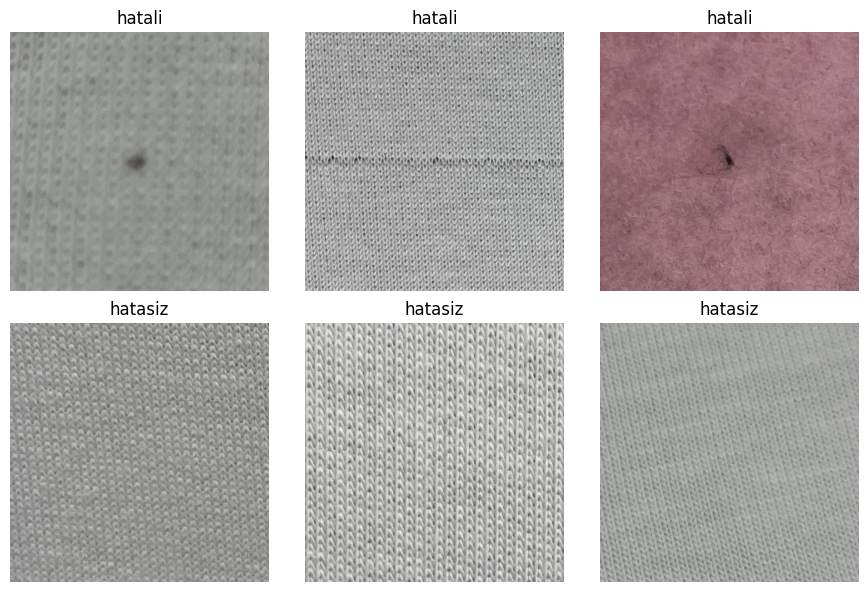

In [ ]:
# ---- Show 3 example images from each class ----
number_of_classes = len(class_names_found)
plt.figure(figsize=(9, 3 * number_of_classes))
plot_number = 1

for class_name in class_names_found:
    # collect the paths that belong to this class
    paths_of_this_class = []
    for path, label in zip(image_paths, image_labels):
        if label == class_name:
            paths_of_this_class.append(path)

    for example_path in paths_of_this_class[:3]:
        plt.subplot(number_of_classes, 3, plot_number)
        plt.imshow(Image.open(example_path))
        plt.title(class_name)
        plt.axis("off")
        plot_number = plot_number + 1

plt.tight_layout()
plt.show()

## 6. Data Preprocessing



In [ ]:
IMAGE_SIZE = 128   # every image becomes 128 x 128 pixels

image_list = []
label_list = []
skipped_images = 0

for path, label in zip(image_paths, image_labels):
    try:
        # load_img opens the image, converts to RGB and resizes it
        image = keras.utils.load_img(path, color_mode="rgb", target_size=(IMAGE_SIZE, IMAGE_SIZE))
        image_array = keras.utils.img_to_array(image)       # picture -> numbers
        image_list.append(image_array.astype("uint8"))      # keep as small integers for now
        label_list.append(label)
    except Exception:
        skipped_images = skipped_images + 1                  # skip damaged files

X = np.array(image_list)
labels_as_text = np.array(label_list)

print("Images loaded:", len(X), "| skipped (unreadable):", skipped_images)
print("Shape of X:", X.shape, "-> (number of images, height, width, channels)")
print("Pixel value range before normalization:", X.min(), "to", X.max())

# ---- Normalization: 0-255  ->  0-1 ----
X = X.astype("float32") / 255.0
print("Pixel value range after normalization: ", X.min(), "to", X.max())

# ---- Label encoding: text -> numbers ----
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels_as_text)
class_names = [str(name) for name in label_encoder.classes_]
number_of_classes = len(class_names)

print()
print("Label encoding:")
for number, name in enumerate(class_names):
    print("  ", number, "=", name)

Images loaded: 2912 | skipped (unreadable): 0
Shape of X: (2912, 128, 128, 3) -> (number of images, height, width, channels)
Pixel value range before normalization: 0 to 255
Pixel value range after normalization:  0.0 to 1.0

Label encoding:
   0 = hatali
   1 = hatasiz


## 7. Train-Test Split

In [ ]:
# Step 1: split off 30% of the data (this will become validation + test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)

# Step 2: split that 30% in half -> 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("Training images:  ", len(X_train))
print("Validation images:", len(X_val))
print("Test images:      ", len(X_test))
print()
print("Images per class in each part:")
for number, name in enumerate(class_names):
    print("  ", name, "-> train:", int(np.sum(y_train == number)),
          "| validation:", int(np.sum(y_val == number)),
          "| test:", int(np.sum(y_test == number)))

Training images:   2038
Validation images: 437
Test images:       437

Images per class in each part:
   hatali -> train: 884 | validation: 189 | test: 190
   hatasiz -> train: 1154 | validation: 248 | test: 247


## 8. CNN Model Architecture

A CNN is built from a few simple building blocks:

| Layer | What it does |
|---|---|
| `RandomFlip`, `RandomRotation` | **Data augmentation.** Randomly flips / rotates training images so the model sees more variety. These are active only during training. |
| `Conv2D` | Slides small 3x3 filters over the image to detect patterns (edges, textures, holes). |
| `ReLU` activation | Keeps positive values and turns negatives into 0. This lets the network learn non-linear patterns. |
| `MaxPooling2D` | Shrinks the image by half, keeping the strongest value in each 2x2 block. Less computation, and small shifts matter less. |
| `Flatten` | Turns the 2D feature maps into one long vector. |
| `Dense` | A normal fully connected layer that combines the features. |
| `Dropout` | Randomly switches off 50% of neurons while training, which reduces overfitting. |
| `Dense` + `softmax` | Output layer: one probability per class. All probabilities add up to 1. |

**Architecture used:** 3 blocks of (Conv + Pool) with 32, 64 and 128 filters, then Flatten, Dense(128), Dropout, and the output layer.

In [ ]:
model = keras.Sequential([
    # Input: a 128 x 128 colour image
    keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3)),

    # Data augmentation (only active during training)
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),

    # Block 1: find simple patterns such as edges
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 2: combine simple patterns into more complex ones
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Block 3: even more complex patterns (textures, holes, stains)
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classifier part
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(number_of_classes, activation="softmax"),   # one output per class
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,898 (12.61 MB)

 Trainable params: 3,304,898 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

## 9. Model Compilation



In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Model compiled.")

Model compiled.


## 10. Model Training



In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",           # watch the validation loss
    patience=5,                   # wait 5 epochs without improvement
    restore_best_weights=True,    # go back to the best epoch
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=[early_stopping],
)

print("Training finished after", len(history.history["loss"]), "epochs.")

Epoch 1/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 25s 380ms/step - accuracy: 0.5770 - loss: 0.6605 - val_accuracy: 0.6636 - val_loss: 0.6058
Epoch 2/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 24s 376ms/step - accuracy: 0.6119 - loss: 0.6321 - val_accuracy: 0.6384 - val_loss: 0.5959
Epoch 3/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 24s 376ms/step - accuracy: 0.6217 - loss: 0.6147 - val_accuracy: 0.7254 - val_loss: 0.4875
Epoch 4/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 24s 374ms/step - accuracy: 0.6541 - loss: 0.5937 - val_accuracy: 0.6453 - val_loss: 0.6172
Epoch 5/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 24s 374ms/step - accuracy: 0.7228 - loss: 0.5656 - val_accuracy: 0.7368 - val_loss: 0.5357
Epoch 6/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 24s 373ms/step - accuracy: 0.7974 - loss: 0.4630 - val_accuracy: 0.8330 - val_loss: 0.5290
Epoch 7/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 24s 374ms/step - accuracy: 0.7812 - loss: 0.4464 - val_accuracy: 0.8673 - val_loss: 0.4058
Epoch 8/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 24s 374ms/step - accuracy: 0.8710 - loss: 0.3448 - val_accu

## 11. Training Performance Visualization


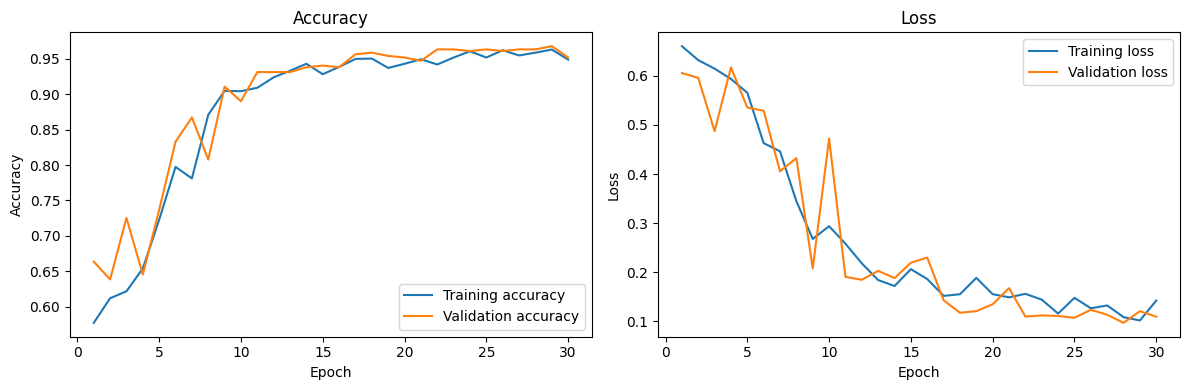

Final training accuracy:   0.949
Final validation accuracy: 0.9519
Final training loss:       0.1426
Final validation loss:     0.1096


In [ ]:
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(train_accuracy) + 1)

plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_accuracy, label="Training accuracy")
plt.plot(epochs_range, val_accuracy, label="Validation accuracy")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_loss, label="Training loss")
plt.plot(epochs_range, val_loss, label="Validation loss")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

print("Final training accuracy:  ", round(train_accuracy[-1], 4))
print("Final validation accuracy:", round(val_accuracy[-1], 4))
print("Final training loss:      ", round(train_loss[-1], 4))
print("Final validation loss:    ", round(val_loss[-1], 4))

## 12. Model Evaluation



In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test loss:    ", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy, 4), "(" + str(round(test_accuracy * 100, 2)) + "%)")

# Predict the class of every test image
# The model outputs one probability per class; argmax picks the class with the highest probability
predicted_probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(predicted_probabilities, axis=1)

Test loss:     0.1122
Test accuracy: 0.9657 (96.57%)


## 13. Confusion Matrix


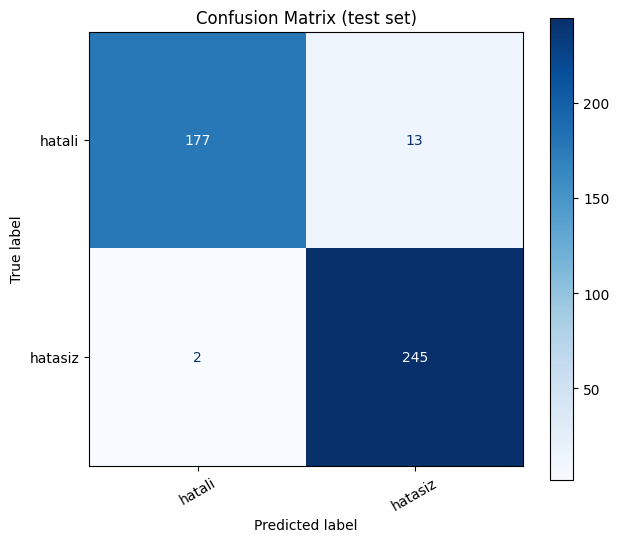

[[177  13]
 [  2 245]]


In [ ]:
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(7, 6))
display.plot(ax=ax, cmap="Blues", xticks_rotation=30)
plt.title("Confusion Matrix (test set)")
plt.show()

print(cm)

## 14. Classification Report



In [ ]:
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

              precision    recall  f1-score   support

      hatali      0.989     0.932     0.959       190
     hatasiz      0.950     0.992     0.970       247

    accuracy                          0.966       437
   macro avg      0.969     0.962     0.965       437
weighted avg      0.967     0.966     0.966       437



## 15. Sample Predictions



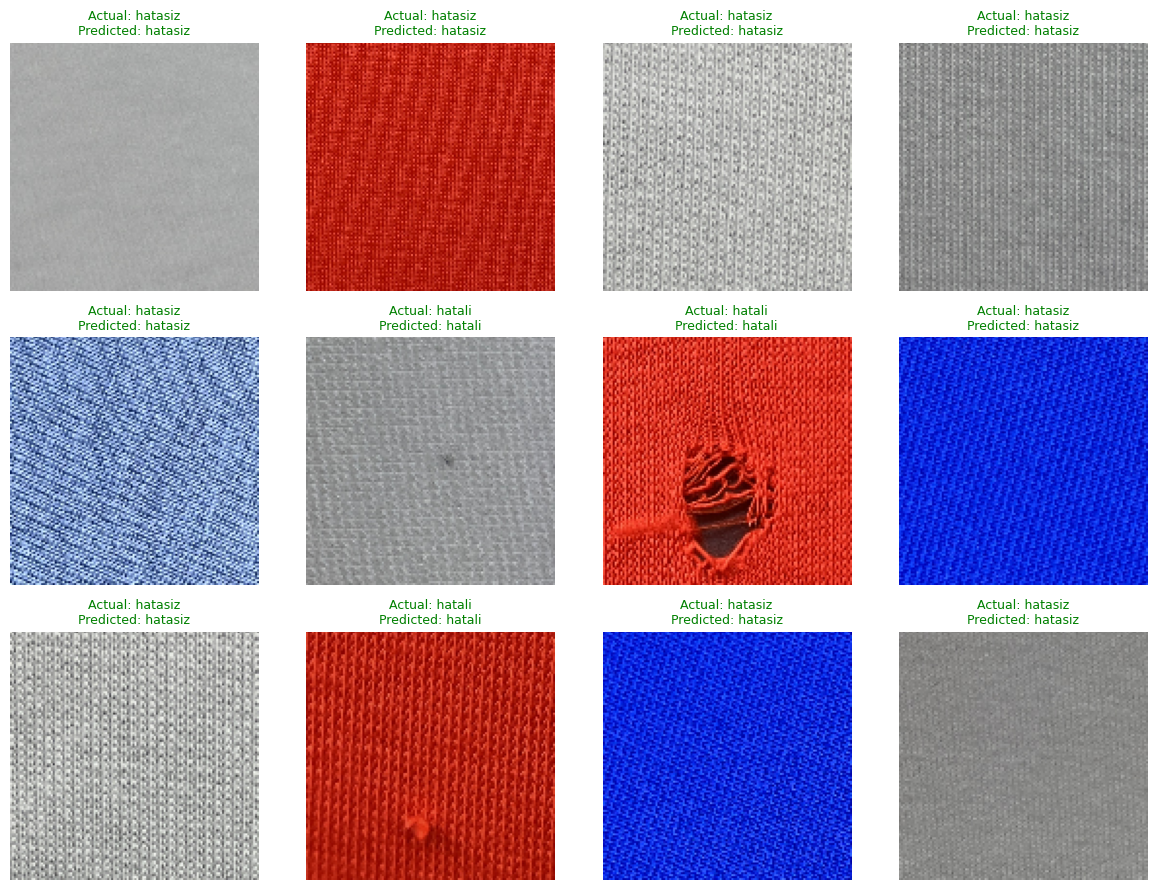

In [ ]:
random_indices = np.random.choice(len(X_test), size=min(12, len(X_test)), replace=False)

plt.figure(figsize=(12, 9))
for position, index in enumerate(random_indices):
    plt.subplot(3, 4, position + 1)
    plt.imshow(X_test[index])                       # images are 0-1, which imshow accepts
    actual_label = class_names[y_test[index]]
    predicted_label = class_names[y_pred[index]]

    if actual_label == predicted_label:
        title_color = "green"
    else:
        title_color = "red"

    plt.title("Actual: " + actual_label + "\nPredicted: " + predicted_label, color=title_color, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

## 16. Final Result Analysis



In [ ]:
report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)

# Best and worst class according to F1-score
best_class = class_names[0]
worst_class = class_names[0]
for name in class_names:
    if report[name]["f1-score"] > report[best_class]["f1-score"]:
        best_class = name
    if report[name]["f1-score"] < report[worst_class]["f1-score"]:
        worst_class = name

# Most common mistake: the biggest number outside the diagonal of the confusion matrix
biggest_mistake = 0
mistake_true = None
mistake_predicted = None
for row in range(number_of_classes):
    for column in range(number_of_classes):
        if row != column and cm[row][column] > biggest_mistake:
            biggest_mistake = cm[row][column]
            mistake_true = class_names[row]
            mistake_predicted = class_names[column]

gap = train_accuracy[-1] - val_accuracy[-1]

print("===== SUMMARY OF RESULTS =====")
print("Dataset: " + str(len(X)) + " images, " + str(number_of_classes) + " classes " + str(class_names))
print("Split: " + str(len(X_train)) + " train / " + str(len(X_val)) + " validation / " + str(len(X_test)) + " test")
print("Epochs run (early stopping): " + str(len(train_accuracy)))
print()
print("Final training accuracy:   " + str(round(train_accuracy[-1] * 100, 2)) + "%")
print("Final validation accuracy: " + str(round(val_accuracy[-1] * 100, 2)) + "%")
print("TEST accuracy:             " + str(round(test_accuracy * 100, 2)) + "%")
print("Macro average F1-score:    " + str(round(report["macro avg"]["f1-score"], 3)))
print()
print("Best class (highest F1):  " + best_class + " (F1 = " + str(round(report[best_class]["f1-score"], 3)) + ")")
print("Worst class (lowest F1):  " + worst_class + " (F1 = " + str(round(report[worst_class]["f1-score"], 3)) + ")")
if mistake_true is not None:
    print("Most common mistake: '" + mistake_true + "' predicted as '" + mistake_predicted + "' (" + str(biggest_mistake) + " images)")
print()

# Simple interpretation rules
if gap > 0.10:
    print("Training accuracy is much higher than validation accuracy (gap " + str(round(gap * 100, 1)) + " points): the model shows OVERFITTING.")
elif test_accuracy < 0.60:
    print("Accuracy is low on all sets: the model is probably UNDERFITTING (too simple, or the classes are hard to tell apart).")
else:
    print("Training and validation accuracy are close: the model generalises reasonably well.")

print()
print("Ideas to improve: more training data, stronger augmentation, a larger image size,")
print("class weights for imbalanced classes, or a slightly deeper CNN.")

===== SUMMARY OF RESULTS =====
Dataset: 2912 images, 2 classes ['hatali', 'hatasiz']
Split: 2038 train / 437 validation / 437 test
Epochs run (early stopping): 30

Final training accuracy:   94.9%
Final validation accuracy: 95.19%
TEST accuracy:             96.57%
Macro average F1-score:    0.965

Best class (highest F1):  hatasiz (F1 = 0.97)
Worst class (lowest F1):  hatali (F1 = 0.959)
Most common mistake: 'hatali' predicted as 'hatasiz' (13 images)

Training and validation accuracy are close: the model generalises reasonably well.

Ideas to improve: more training data, stronger augmentation, a larger image size,
class weights for imbalanced classes, or a slightly deeper CNN.
